# 02 — Preprocessing (fixed): ignore handling, reproducible eval, augmentation plan

Closes the *Data Understanding and Preprocessing* checkpoint:
1. Rebuilds COCO GT so ignore regions are `iscrowd=1`.
2. Re-runs 4-strategy comparison on the same 200-frame eval subset.
3. Locks `chosen_preprocessing.json`.
4. Documents augmentation plan reused by all detector notebooks.
5. Smoke-tests the submission writer.

Inputs:
- Competition data: `/kaggle/input/competitions/multiple-object-video-detection-hw-2-ucu-ai-2026/`
- Custom dataset: `/kaggle/input/datasets/suchok/my-dataset/`
- Previous artifacts: `/kaggle/input/datasets/suchok/outputs_1/`

## 1. Setup

In [1]:
import sys, json, time
from pathlib import Path

import numpy as np
import pandas as pd
import cv2
import matplotlib.pyplot as plt
import torch

COMP_DIR    = Path("/kaggle/input/competitions/multiple-object-video-detection-hw-2-ucu-ai-2026")
DATASET_DIR = Path("/kaggle/input/datasets/suchok/my-dataset")
OUTPUTS_DIR = Path("/kaggle/input/datasets/suchok/outputs-1")
WORK_DIR    = Path("/kaggle/working")

assert COMP_DIR.exists(), f"Missing competition folder: {COMP_DIR}"
assert DATASET_DIR.exists(), f"Missing my-dataset folder: {DATASET_DIR}"
assert OUTPUTS_DIR.exists(), f"Missing outputs_1 folder: {OUTPUTS_DIR}"

WORK_DIR.mkdir(parents=True, exist_ok=True)

COMMON_PATH = DATASET_DIR / "common.py"
assert COMMON_PATH.exists(), f"Missing common.py at: {COMMON_PATH}"
sys.path.insert(0, str(DATASET_DIR))

import common, importlib
importlib.reload(common)
from common import *

set_seeds(SEED)

TRAIN_DIR = COMP_DIR / "train"
VAL_DIR   = COMP_DIR / "val"
TEST_CSV  = COMP_DIR / "test_images.csv"

print("TRAIN_DIR:", TRAIN_DIR, "| exists:", TRAIN_DIR.exists())
print("VAL_DIR:  ", VAL_DIR,   "| exists:", VAL_DIR.exists())
print("TEST_CSV: ", TEST_CSV, "| exists:", TEST_CSV.exists())

weight_candidates = list(DATASET_DIR.glob("fasterrcnn_resnet50_fpn_v2_coco*.pth"))
assert len(weight_candidates) == 1, f"Expected 1 weight file, found: {weight_candidates}"
PRETRAINED_FRCNN = weight_candidates[0]
print("Weights:", PRETRAINED_FRCNN.name)

TRAIN_DIR: /kaggle/input/competitions/multiple-object-video-detection-hw-2-ucu-ai-2026/train | exists: True
VAL_DIR:   /kaggle/input/competitions/multiple-object-video-detection-hw-2-ucu-ai-2026/val | exists: True
TEST_CSV:  /kaggle/input/competitions/multiple-object-video-detection-hw-2-ucu-ai-2026/test_images.csv | exists: True
Weights: fasterrcnn_resnet50_fpn_v2_coco-dd69338a.pth


In [2]:
train_index = index_split(TRAIN_DIR)
val_index   = index_split(VAL_DIR)

SPLITS_DIR = OUTPUTS_DIR / "splits"
train_clips, val_clips = load_splits(SPLITS_DIR)

seen_train = set(train_index["clip"].unique())
seen_val   = set(val_index["clip"].unique())

assert set(train_clips) == seen_train, "train split mismatch"
assert set(val_clips)   == seen_val,   "val split mismatch"
assert set(train_clips).isdisjoint(set(val_clips)), "clip leakage"

save_splits(train_clips, val_clips, WORK_DIR / "splits")

print(f"train: {len(train_index):,} frames / {len(train_clips)} clips")
print(f"val  : {len(val_index):,} frames / {len(val_clips)} clips")

val_index = read_image_sizes(val_index, desc="val sizes")
print(val_index[["clip","width","height"]].drop_duplicates().to_string(index=False))

train: 24,201 frames / 56 clips
val  : 2,846 frames / 7 clips


val sizes:   0%|          | 0/2846 [00:00<?, ?it/s]

              clip  width  height
uav0000086_00000_v   1344     756
uav0000117_02622_v   2720    1530
uav0000137_00458_v   2688    1512
uav0000182_00000_v   1344     756
uav0000268_05773_v   3840    2160
uav0000305_00000_v   1904    1071
uav0000339_00001_v   1904    1071


In [3]:
EVAL_SUBSET = make_eval_subset(val_index, n=200, seed=SEED)
print("Eval subset:", len(EVAL_SUBSET), "| clips:", EVAL_SUBSET["clip"].nunique())

Eval subset: 200 | clips: 7


In [4]:
gt_ignore   = WORK_DIR / "gt_eval_subset_ignore.json"
gt_noignore = WORK_DIR / "gt_eval_subset_noignore.json"

build_coco_gt(EVAL_SUBSET, gt_ignore,   include_ignore=True)
build_coco_gt(EVAL_SUBSET, gt_noignore, include_ignore=False)

def count_crowd(p):
    d = json.load(open(p))
    n = sum(a["iscrowd"] == 1 for a in d["annotations"])
    m = sum(a["iscrowd"] == 0 for a in d["annotations"])
    return m, n

m1, n1 = count_crowd(gt_noignore)
m2, n2 = count_crowd(gt_ignore)
print(f"noignore: {m1:,} normal, 0 crowd")
print(f"ignore  : {m2:,} normal, {n2:,} crowd")

noignore: 7,672 normal, 0 crowd
ignore  : 7,672 normal, 244 crowd


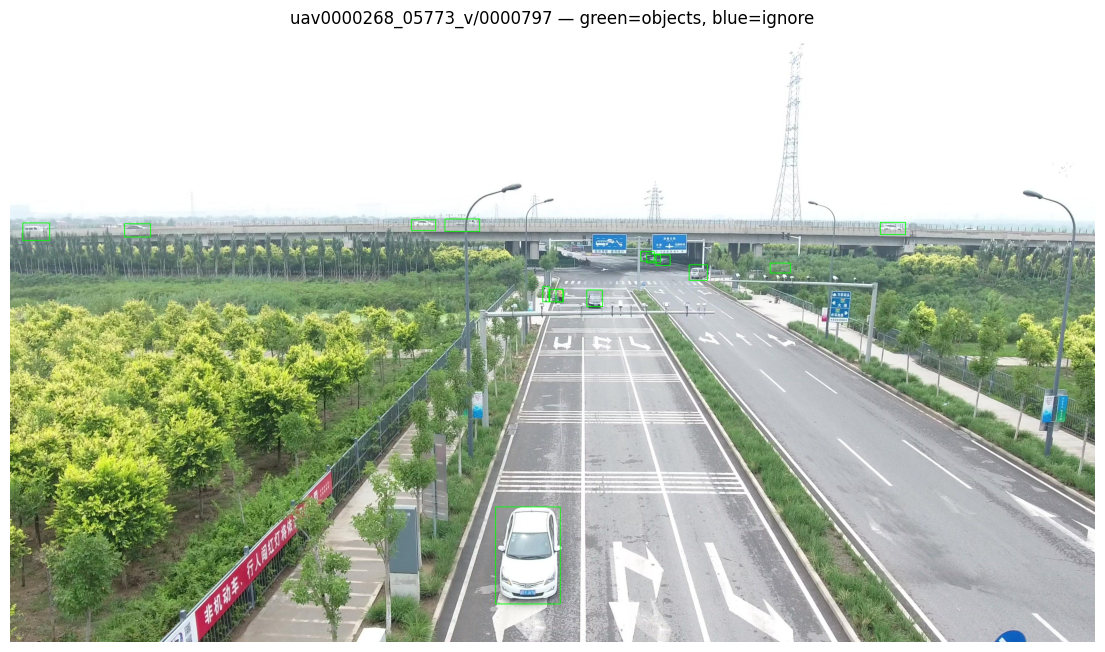

objects: 15 | ignore regions: 0


In [5]:
row = val_index.sample(1, random_state=SEED).iloc[0]
img = cv2.cvtColor(cv2.imread(row["image_path"]), cv2.COLOR_BGR2RGB)
h, w = img.shape[:2]

boxes, _ = load_yolo_labels(row["label_path"], w, h)
ign      = load_ignore_regions(row["ignore_path"], w, h)

vis = img.copy()
for x1, y1, x2, y2 in boxes:
    cv2.rectangle(vis, (int(x1), int(y1)), (int(x2), int(y2)), (0, 255, 0), 2)
for x1, y1, x2, y2 in ign:
    cv2.rectangle(vis, (int(x1), int(y1)), (int(x2), int(y2)), (255, 0, 0), 3)

plt.figure(figsize=(14, 8))
plt.imshow(vis)
plt.title(f"{row['clip']}/{row['frame']} — green=objects, blue=ignore")
plt.axis("off"); plt.show()
print(f"objects: {len(boxes)} | ignore regions: {len(ign)}")

In [6]:
from torchvision.models.detection import fasterrcnn_resnet50_fpn_v2

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
state_dict = torch.load(PRETRAINED_FRCNN, map_location="cpu")
detector = fasterrcnn_resnet50_fpn_v2(weights=None).to(DEVICE)
detector.load_state_dict(state_dict)
detector.eval()
print("Detector loaded on", DEVICE)

Detector loaded on cuda


In [7]:
sample_paths = train_index.sample(min(2000, len(train_index)),
                                  random_state=SEED)["image_path"]
max_w, max_h = 0, 0
for p in sample_paths:
    h, w = cv2.imread(p, cv2.IMREAD_UNCHANGED).shape[:2]
    max_w, max_h = max(max_w, w), max(max_h, h)
CANVAS_SIZE = (max_w, max_h)
print("CANVAS_SIZE:", CANVAS_SIZE)

CANVAS_SIZE: (2720, 1530)


In [8]:
STRATEGIES = [
    ("letterbox", 1024),
    ("letterbox", 1280),
    ("plain",     1280),
    ("randompad", CANVAS_SIZE),
]

rows = []
for strat, sz in STRATEGIES:
    t0 = time.time()
    n_pred = 0
    for _, r in EVAL_SUBSET.iterrows():
        b, _, _, _, _ = predict_with_strategy(detector, r["image_path"],
                                              strat, sz, score_thr=0.001,
                                              device=DEVICE)
        n_pred += len(b)
    dt = time.time() - t0

    pred_json = WORK_DIR / f"pred_eval_{strat}_{sz}.json"
    predictions_to_coco(EVAL_SUBSET, detector, strat, sz, str(pred_json),
                        score_thr=0.001, device=DEVICE)

    m_no = coco_eval_summary(str(gt_noignore), str(pred_json))
    m_ig = coco_eval_summary(str(gt_ignore),   str(pred_json))

    rows.append({
        "strategy": strat, "size": str(sz),
        "mean_preds": n_pred / len(EVAL_SUBSET),
        "infer_s": dt / len(EVAL_SUBSET),
        "mAP_noignore": m_no["mAP"], "AP50_noignore": m_no["AP50"],
        "mAP_ignore":   m_ig["mAP"], "AP50_ignore":   m_ig["AP50"],
        "AP_small_ignore": m_ig["AP_small"],
    })

comparison = pd.DataFrame(rows).sort_values("mAP_ignore", ascending=False)
comparison.to_csv(WORK_DIR / "resize_strategy_comparison_ignore.csv", index=False)
comparison

pred letterbox-1024:   0%|          | 0/200 [00:00<?, ?it/s]

pred letterbox-1280:   0%|          | 0/200 [00:00<?, ?it/s]

pred plain-1280:   0%|          | 0/200 [00:00<?, ?it/s]

pred randompad-(2720, 1530):   0%|          | 0/200 [00:00<?, ?it/s]

,strategy,size,mean_preds,infer_s,mAP_noignore,AP50_noignore,mAP_ignore,AP50_ignore,AP_small_ignore
1,letterbox,1280,40.680,0.217940,0.012470,0.026811,0.012533,0.027052,0.010950
0,letterbox,1024,39.990,0.240831,0.012170,0.025378,0.012231,0.025614,0.011035
3,randompad,"(2720, 1530)",46.655,0.351562,0.011553,0.024746,0.011597,0.024908,0.008984
2,plain,1280,51.540,0.216641,0.008277,0.017511,0.008304,0.017621,0.008083


In [9]:
best = comparison.iloc[0]
chosen = {
    "strategy": best["strategy"],
    "size": int(best["size"]),
    "mAP_ignore": float(best["mAP_ignore"]),
    "AP50_ignore": float(best["AP50_ignore"]),
    "AP_small_ignore": float(best["AP_small_ignore"]),
    "notes": "chosen on 200-frame eval subset with iscrowd=1 ignore",
}
json.dump(chosen, open(WORK_DIR / "chosen_preprocessing.json", "w"), indent=2)
print(json.dumps(chosen, indent=2))

{
  "strategy": "letterbox",
  "size": 1280,
  "mAP_ignore": 0.01253286997837542,
  "AP50_ignore": 0.02705221597217152,
  "AP_small_ignore": 0.010949753450417026,
  "notes": "chosen on 200-frame eval subset with iscrowd=1 ignore"
}


In [10]:
test_df = pd.read_csv(TEST_CSV)
print("test rows:", len(test_df)); display(test_df.head())

smoke_csv = WORK_DIR / "test_smoke.csv"
test_df.head(5).to_csv(smoke_csv, index=False)

sub_smoke = predict_test_and_write_submission(
    test_csv=smoke_csv,
    detector=detector,
    strategy=chosen["strategy"],
    size=int(chosen["size"]),
    out_csv=WORK_DIR / "submission_smoke.csv",
    score_thr=0.05,
    max_dets=500,
    device=DEVICE,
    data_root=COMP_DIR,
)
sub_smoke.head()

test rows: 3811


,image_id,file_name,clip,frame,width,height
0,clip_001_0000001,test/images/clip_001/0000001.jpg,clip_001,1,1920,1080
1,clip_001_0000002,test/images/clip_001/0000002.jpg,clip_001,2,1920,1080
2,clip_001_0000003,test/images/clip_001/0000003.jpg,clip_001,3,1920,1080
3,clip_001_0000004,test/images/clip_001/0000004.jpg,clip_001,4,1920,1080
4,clip_001_0000005,test/images/clip_001/0000005.jpg,clip_001,5,1920,1080


test inference:   0%|          | 0/5 [00:00<?, ?it/s]

,image_id,PredictionString
0,clip_001_0000001,0 0.6923 834.3 718.6 42.8 105.0 0 0.6171 1022....
1,clip_001_0000002,0 0.7073 1024.7 674.2 26.3 60.3 0 0.7046 836.2...
2,clip_001_0000003,0 0.8649 832.2 720.3 39.7 102.5 0 0.5692 973.2...
3,clip_001_0000004,0 0.8193 822.5 721.6 39.8 104.0 0 0.4767 963.7...
4,clip_001_0000005,0 0.8994 799.4 725.7 36.0 101.5 0 0.6473 967.4...


In [11]:
def validate_row(s, width, height):
    if not isinstance(s, str) or s == "":
        return True
    parts = s.strip().split()
    if len(parts) % 6: return False
    for i in range(0, len(parts), 6):
        cls = int(parts[i]); score = float(parts[i+1])
        x, y, w_box, h_box = map(float, parts[i+2:i+6])
        if not (0 <= cls <= 7): return False
        if not (0 <= score <= 1): return False
        if w_box <= 0 or h_box <= 0: return False
        if x < 0 or y < 0: return False
        if x + w_box > width + 1 or y + h_box > height + 1: return False
    return True

all_ok = all(
    validate_row(r["PredictionString"],
                 test_df.loc[test_df.image_id == r["image_id"], "width"].iloc[0],
                 test_df.loc[test_df.image_id == r["image_id"], "height"].iloc[0])
    for _, r in sub_smoke.iterrows()
)
print("All smoke rows valid:", all_ok)

All smoke rows valid: True
